# Bike Sharing Demand – Bisiklet Kiralama Talebi Tahmini
Tarih-saat ve hava durumu bilgilerini kullanarak bir saatte kaç bisiklet kiralanacağını tahmin etmek.Denetimli Öğrenme – Regresyon kullanacağız.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Eğitim verisi:", train.shape)
print("Test verisi:", test.shape)
display(train.head())

Eğitim verisi: (10886, 12)
Test verisi: (6493, 9)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [4]:
display(train.isnull().sum().to_frame("Eksik değer sayısı"))
display(train.describe().T)

,Eksik değer sayısı
datetime,0
season,0
holiday,0
workingday,0
weather,0
temp,0
atemp,0
humidity,0
windspeed,0
casual,0


,count,mean,std,min,25%,50%,75%,max
season,10886.0,2.506614,1.116174,1.00,2.0000,3.000,4.0000,4.0000
holiday,10886.0,0.028569,0.166599,0.00,0.0000,0.000,0.0000,1.0000
workingday,10886.0,0.680875,0.466159,0.00,0.0000,1.000,1.0000,1.0000
weather,10886.0,1.418427,0.633839,1.00,1.0000,1.000,2.0000,4.0000
temp,10886.0,20.230860,7.791590,0.82,13.9400,20.500,26.2400,41.0000
atemp,10886.0,23.655084,8.474601,0.76,16.6650,24.240,31.0600,45.4550
humidity,10886.0,61.886460,19.245033,0.00,47.0000,62.000,77.0000,100.0000
windspeed,10886.0,12.799395,8.164537,0.00,7.0015,12.998,16.9979,56.9969
casual,10886.0,36.021955,49.960477,0.00,4.0000,17.000,49.0000,367.0000
registered,10886.0,155.552177,151.039033,0.00,36.0000,118.000,222.0000,886.0000


## 4. Hedef değişkeni inceleme

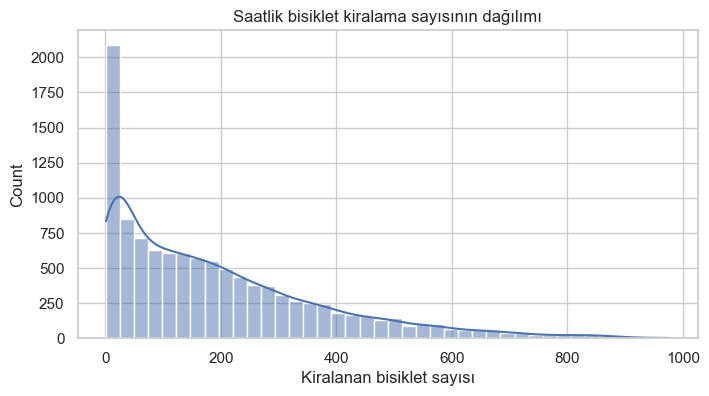

In [5]:
plt.figure(figsize=(8, 4))
sns.histplot(train["count"], bins=40, kde=True)
plt.title("Saatlik bisiklet kiralama sayısının dağılımı")
plt.xlabel("Kiralanan bisiklet sayısı")
plt.show()

In [6]:
def ozellik_olustur(df):
    df = df.copy()
    df["datetime"] = pd.to_datetime(df["datetime"])
    df["year"] = df["datetime"].dt.year
    df["month"] = df["datetime"].dt.month
    df["day"] = df["datetime"].dt.day
    df["hour"] = df["datetime"].dt.hour
    df["dayofweek"] = df["datetime"].dt.dayofweek
    df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
    return df

train = ozellik_olustur(train)
test = ozellik_olustur(test)

display(train[["datetime", "hour", "dayofweek", "is_weekend", "count"]].head())

,datetime,hour,dayofweek,is_weekend,count
0,2011-01-01 00:00:00,0,5,1,16
1,2011-01-01 01:00:00,1,5,1,40
2,2011-01-01 02:00:00,2,5,1,32
3,2011-01-01 03:00:00,3,5,1,13
4,2011-01-01 04:00:00,4,5,1,1


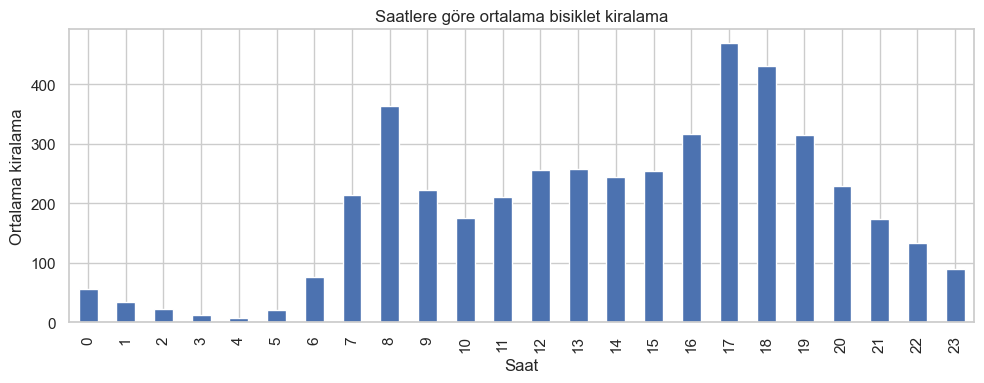

In [14]:
saatlik = train.groupby("hour")["count"].mean()
plt.figure(figsize=(10, 4))
saatlik.plot(kind="bar")
plt.title("Saatlere göre ortalama bisiklet kiralama")
plt.xlabel("Saat")
plt.ylabel("Ortalama kiralama")
plt.tight_layout();

In [8]:
hedef = "count"

gereksiz = ["count", "casual", "registered", "datetime"]
x = train.drop(columns=[c for c in gereksiz if c in train.columns])
y = train[hedef]

x_test = test.drop(columns=[c for c in ["casual", "registered", "datetime"] if c in test.columns])

# Sütunların sırasını eğitim verisiyle aynı yap
x_test = x_test.reindex(columns=x.columns, fill_value=0)

print("Model girdileri:", list(x.columns))
print("Eğitim özellikleri:", x.shape)

Model girdileri: ['season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'year', 'month', 'day', 'hour', 'dayofweek', 'is_weekend']
Eğitim özellikleri: (10886, 14)


In [9]:
x_train, x_valid, y_train, y_valid = train_test_split(
    x, y, test_size=0.2, random_state=42
)

print("Eğitim satırı:", x_train.shape[0])
print("Doğrulama satırı:", x_valid.shape[0])

Eğitim satırı: 8708
Doğrulama satırı: 2178


In [10]:
modeller = {
    "Random Forest": RandomForestRegressor(
        n_estimators=250, min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=250, min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=200, learning_rate=0.08, random_state=42
    )
}

sonuclar = []
egitilmis_modeller = {}

for isim, model in modeller.items():
    model.fit(X_train, y_train)
    tahmin = np.maximum(model.predict(X_valid), 0)
    mae = mean_absolute_error(y_valid, tahmin)
    rmse = np.sqrt(mean_squared_error(y_valid, tahmin))
    r2 = r2_score(y_valid, tahmin)
    sonuclar.append([isim, mae, rmse, r2])
    egitilmis_modeller[isim] = model

sonuc_df = pd.DataFrame(sonuclar, columns=["Model", "MAE", "RMSE", "R2"])
sonuc_df.sort_values("RMSE")

,Model,MAE,RMSE,R2
2,Gradient Boosting,22.883230,35.595053,0.961614
1,Extra Trees,24.174806,37.915492,0.956446
0,Random Forest,24.392134,38.983976,0.953957


**Metrikleri yorumlama**
- **MAE:** Tahminlerin gerçek değerden ortalama kaç bisiklet saptığını gösterir. Düşük olması iyidir.
- **RMSE:** Büyük hataları daha fazla cezalandırır. Düşük olması iyidir.
- **R²:** Modelin değişimi ne ölçüde açıkladığını gösterir. Genellikle 1'e yaklaştıkça iyidir.

Rastgele eğitim/doğrulama bölmesi, başlangıç için basit bir değerlendirmedir; zaman serilerinde daha gerçekçi test için kronolojik doğrulama da yapılabilir.

In [11]:
en_iyi_isim = sonuc_df.sort_values("RMSE").iloc[0]["Model"]
en_iyi_model = egitilmis_modeller[en_iyi_isim]

print("En iyi doğrulama modeli:", en_iyi_isim)
joblib.dump(en_iyi_model, "bike_sharing_model.pkl")
joblib.dump(list(X.columns), "model_columns.pkl")
print("Model kaydedildi.")

En iyi doğrulama modeli: Gradient Boosting
Model kaydedildi.


In [18]:
valid_tahmin = np.maximum(en_iyi_model.predict(X_valid), 0)

karsilastirma = pd.DataFrame({
    "Gerçek değer": y_valid.values[:20],
    "Tahmin": valid_tahmin[:20].round().astype(int)
})
display(karsilastirma)

,Gerçek değer,Tahmin
0,127,124
1,13,0
2,163,149
3,233,205
4,222,204
5,166,169
6,144,156
7,376,370
8,601,675
9,53,67


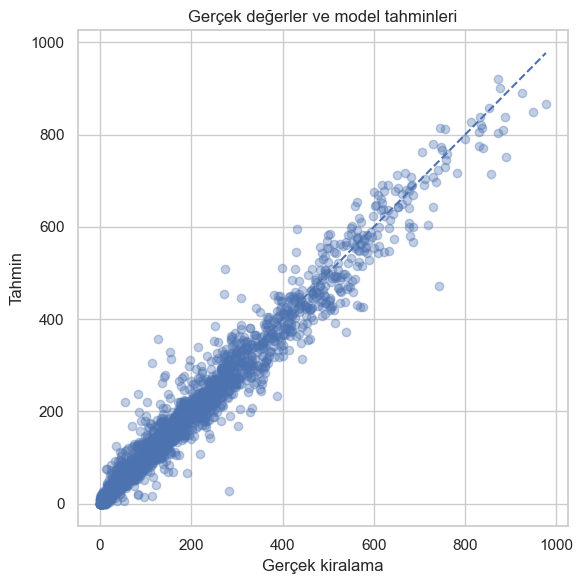

In [19]:
plt.figure(figsize=(6, 6))
plt.scatter(y_valid, valid_tahmin, alpha=0.35)
ust = max(y_valid.max(), valid_tahmin.max())
plt.plot([0, ust], [0, ust], "--")
plt.xlabel("Gerçek kiralama")
plt.ylabel("Tahmin")
plt.title("Gerçek değerler ve model tahminleri")
plt.tight_layout()

In [16]:
test_tahmin = np.maximum(en_iyi_model.predict(X_test), 0)

submission = pd.DataFrame({
    "datetime": test["datetime"],
    "count": test_tahmin
})

In [17]:
submission.to_csv("submission.csv", index=False)
display(submission.head())
print("submission.csv oluşturuldu.")

,datetime,count
0,2011-01-20 00:00:00,11.923142
1,2011-01-20 01:00:00,0.000000
2,2011-01-20 02:00:00,0.000000
3,2011-01-20 03:00:00,0.000000
4,2011-01-20 04:00:00,0.000000


submission.csv oluşturuldu.


Bu çalışmada bisiklet kiralama talebini tahmin etmek için regresyon modelleri kuruldu. Tarih-saat alanından yeni özellikler üretildi, modeller aynı doğrulama verisi üzerinde MAE, RMSE ve R² ile karşılaştırıldı ve en iyi model kaydedildi. 